In [198]:
import random

from pydantic import BaseModel, Field
from IPython.display import Markdown
import sympy as sp
from sympy import S as S_module
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import numpy as np

In [199]:
class ModelParams(BaseModel):
    K: float = Field(ge=0.0, le=1.0, default=1.0, description="Емкость среды")
    D_max: float = Field(ge=0.001, le=1.0, default=1.0, description="Максимальная переносимая доза (MTD)")
    r_S: float = Field(ge=0.0, le=1.0, default=0.027, description="Скорость размножения S-клеток")
    r_R: float = Field(ge=0.5, le=1.0, description="Скорость размножения R-клеток")
    d_T: float = Field(ge=0.0, le=0.3, description="Скорость обновления раковых клеток")
    d_D: float = Field(ge=0.0, le=2.0, default=1.5, description="Удвоенная вероятность уничтожения раковой клетки при MTD")
    n_0: float = Field(ge=0.1, le=0.75, description="Начальная плотность опухлевых клеток")
    f_R: float = Field(ge=0.001, le=0.1, description="Доля R-клеток от общего количества раковых клеток")
    f_S: float = Field(ge=0.9, le=0.999, description="Доля R-клеток от общего количества раковых клеток")

def generate_model_params() -> ModelParams:
    f_R = random.randint(1, 100) / 1000

    return ModelParams(
        r_R = random.randint(50, 100) / 100,
        d_T = random.randint(0, 30) / 100,
        n_0 = random.randint(10, 75) / 100,
        f_R = f_R,
        f_S = 1 - f_R,
    )

model_params = generate_model_params()

In [200]:
markdown_text = """## Параметры модели\n""" \
    """|Параметр|Описание|Значение|\n""" \
    """|---|---|---|\n"""

for name, field_info in ModelParams.model_fields.items():
    markdown_text += \
        f"""|{name.replace("_", "<sub>") + "</sub>" if "_" in name else name}|""" \
        f"""{field_info.description or " "}|{getattr(model_params, name)}|\n"""

display(Markdown(markdown_text))

## Параметры модели
|Параметр|Описание|Значение|
|---|---|---|
|K|Емкость среды|1.0|
|D<sub>max</sub>|Максимальная переносимая доза (MTD)|1.0|
|r<sub>S</sub>|Скорость размножения S-клеток|0.027|
|r<sub>R</sub>|Скорость размножения R-клеток|0.81|
|d<sub>T</sub>|Скорость обновления раковых клеток|0.04|
|d<sub>D</sub>|Удвоенная вероятность уничтожения раковой клетки при MTD|1.5|
|n<sub>0</sub>|Начальная плотность опухлевых клеток|0.74|
|f<sub>R</sub>|Доля R-клеток от общего количества раковых клеток|0.014|
|f<sub>S</sub>|Доля R-клеток от общего количества раковых клеток|0.986|


In [201]:
S, R = sp.symbols("S R", real=True)
K, D_max, r_S, r_R, d_T, d_D, n_0, f_R, f_S = sp.symbols(
    "K D_max r_S r_R d_T d_D n_0 f_R f_S", positive=True
)

dS = r_S * (1 - (S + R) / K) * (1 - 2*d_D / D_max) * S - d_T * S
dR = r_R * (1 - (S + R) / K) * R - d_T * R


In [202]:
equilibrium_points = sp.solve([dS, dR], [S, R], dict=True)

for p in equilibrium_points:
    for n, v in p.items():
        p[n] = sp.N(v.subs({
            K: model_params.K, 
            D_max: model_params.D_max, 
            r_S: model_params.r_S, 
            r_R: model_params.r_R, 
            d_T: model_params.d_T, 
            d_D: model_params.d_D, 
            n_0: model_params.n_0, 
            f_R: model_params.f_R, 
            f_S: model_params.f_S
        }))

In [218]:
def system(t: float, y: tuple[float, float]) -> tuple[float, float]:
    S, R = y
    D = model_params.D_max

    return (
        (
            model_params.r_S * (1 - (S + R) / model_params.K) * 
            (1 - 2 * model_params.d_D / model_params.D_max * D) * 
            S - model_params.d_T * S
        ),
        model_params.r_R * (1 - (S + R) / model_params.K) * R - model_params.d_T * R
    )

S_eval = np.linspace(0, 1.1, num=25)
R_eval = np.linspace(0, 1.1, num=25)
S_grid, R_grid = np.meshgrid(S_eval, R_eval)
dS = (
    model_params.r_S * (1 - (S_grid + R_grid) / model_params.K) * 
    (1 - 2 * model_params.d_D / model_params.D_max * model_params.D_max) * 
    S_grid - model_params.d_T * S_grid
)
dR = model_params.r_R * (1 - (S_grid + R_grid) / model_params.K) * R_grid - model_params.d_T * R_grid
initial_conditions = [
    (0.1, 0.1),
    (0.375, 0.375),
    (0.25, 0.5),
    (0.5, 0.25),
    (0.25, 0.25),
    (0.125, 0.7),
    (0.7, 0.125)
]

In [208]:
solutions = []

for y0 in initial_conditions:
    solutions.append(
        solve_ivp(system, (0, 100), y0, max_step=0.1, rtol=1e-8, atol=1e-10)
    )

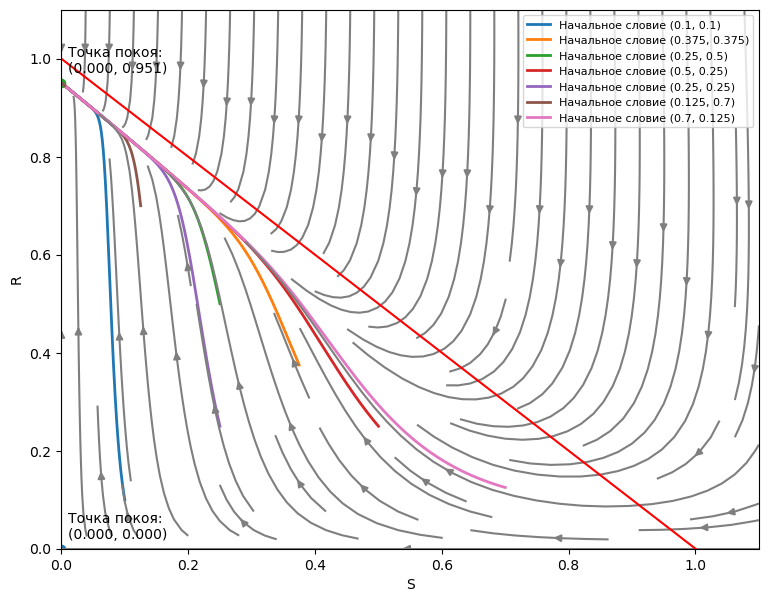

In [221]:
plt.figure(figsize=(9, 7))

for p in equilibrium_points:
    ordinate = -1
    abscissa = -1

    for n, v in p.items():
        if n == R:
            ordinate = v
        else:
            abscissa = v

    plt.scatter(abscissa, ordinate)
    plt.annotate(
        f'Точка покоя:\n({abscissa:.3f}, {ordinate:.3f})',
        (abscissa, ordinate),
        xytext=(5, 7),
        textcoords='offset points'
    )

for sol, y0 in zip(solutions, initial_conditions):
    plt.plot(sol.y[0], sol.y[1], label=f"Начальное словие {y0}", linewidth=2.0)

plt.streamplot(S_grid, R_grid, dS, dR)

plt.plot((0, 1), (1, 0), color="red")

plt.xlabel("S")
plt.ylabel("R")
plt.xlim(0, 1.1)
plt.ylim(0, 1.1)
plt.legend(fontsize=8)
plt.plot()
plt.show()